# LuzViva - Detector de luminárias

O modelo analisa uma imagem de rua e classifica cada luminária como **acesa** ou **apagada**.

Etapas (funções em `visao.py`):
1. **Dataset** (`contar`): imagens de rua com cada luminária anotada por uma caixa.
2. **Treinamento** (`treinar`): o YOLO11n, rede neural convolucional pré-treinada, é ajustado às 2 classes do projeto.
3. **Detecção** (`detectar`): recebe uma imagem e retorna as caixas; a interface web (`app.py`) usa a mesma função.

In [1]:
import os, time, shutil
os.environ["YOLO_VERBOSE"] = "False"  # esconde as mensagens do YOLO
import cv2, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO
from visao import contar, treinar, detectar, desenhar, PASTA, DATASET, CLASSES

# mostra uma imagem do OpenCV (BGR) no notebook
def mostrar(img):
    plt.figure(figsize=(12, 7)); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()

## 0. Teste rápido

Troque o arquivo e execute a célula. Cada luminária retorna com a classe, a confiança (0 a 1) e a caixa em pixels.

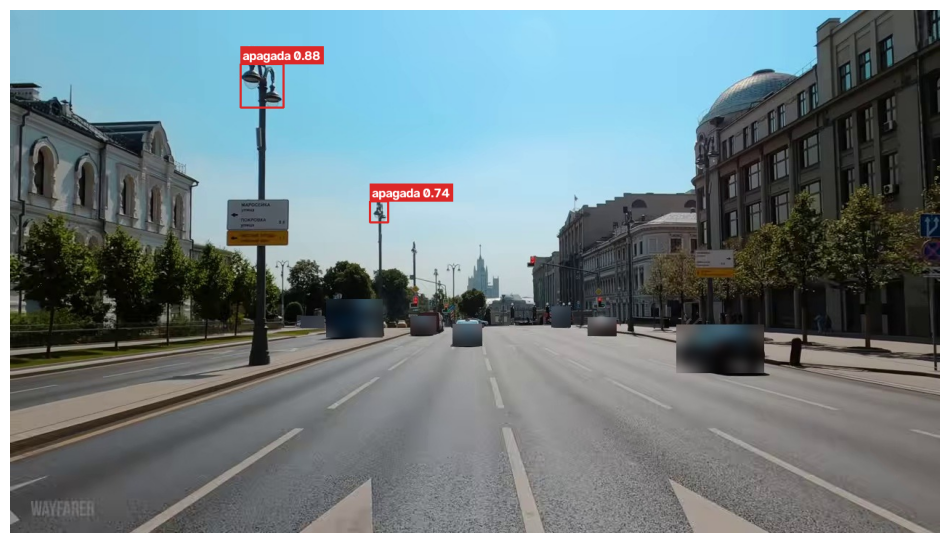

[{'classe': 'apagada', 'confianca': 0.88, 'caixa': [317, 74, 376, 134]},
 {'classe': 'apagada', 'confianca': 0.74, 'caixa': [495, 263, 520, 292]}]

In [2]:
foto = cv2.imread("exemplos/01_apagada_6_00390.jpg")
luminarias = detectar(foto)
mostrar(desenhar(foto, luminarias))
luminarias

## 1. Dataset

A pasta `dataset/` já está dividida em treino, validação e teste e reúne duas fontes:

**Lamp State Detection** ([Hugging Face](https://huggingface.co/datasets/ngocleltt/lamp-state-detection), CC BY 4.0):
quadros de vídeos de rua com cada luminária anotada como acesa ou apagada.
- 8 dos 10 vídeos; os outros 2 foram descartados por apresentarem neve.
- Quadros consecutivos são quase idênticos, então manteve-se 1 a cada 6 (1 a cada 2 nos que têm luminária apagada, mais raros).
- Divisão 70/15/15 em blocos de 10 quadros consecutivos, para o teste não ter imagens quase iguais às do treino.

**Imagens complementares do Roboflow** (CC BY 4.0, apenas no treino), pois o dataset principal tem poucas cenas noturnas:
- 70 imagens noturnas com luminárias acesas anotadas (`noite_XX`, street_light_on);
- 26 imagens noturnas com luminárias apagadas, **anotadas manualmente pela equipe** (`apagada_XX`, street-light-off);
- 4 imagens diurnas com luminárias apagadas bem anotadas (`dia_XX`, street-light-off).

In [3]:
contagem = contar()
pd.DataFrame(contagem).T  # imagens e caixas de cada classe em cada conjunto

,imagens,acesa,apagada
train,1171,3108,555
val,181,235,142
test,178,265,89


Cada imagem tem um `.txt` com uma linha por luminária: `classe x_centro y_centro largura altura` (de 0 a 1), formato
do YOLO exportado também pelo Roboflow. Anotações da imagem acima:

1 0.395486 0.385099 0.018274 0.040561
1 0.267678 0.137352 0.040378 0.069439



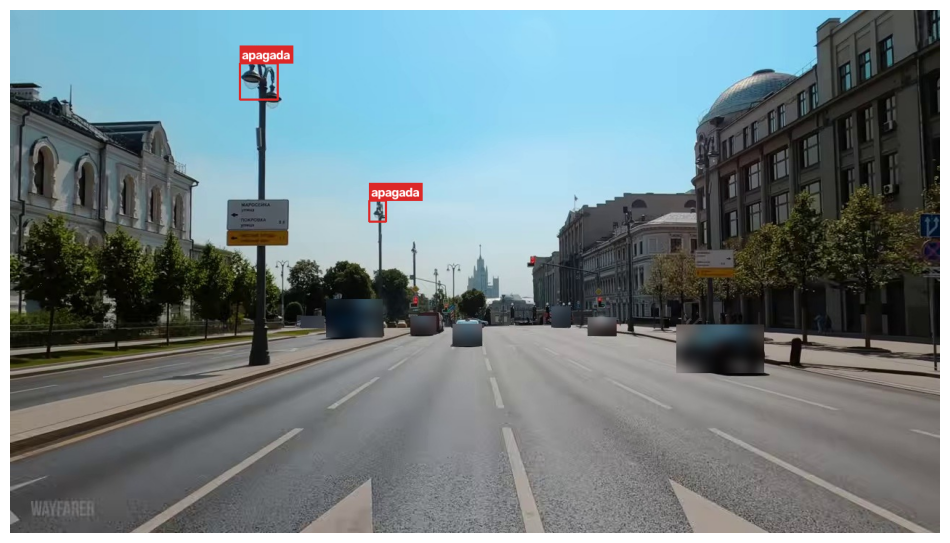

In [4]:
texto = (DATASET / "test" / "labels" / "6_00390.txt").read_text()
print(texto)
h, w = foto.shape[:2]
marcadas = []
for linha in texto.splitlines():  # converte de 0-1 para pixels
    c, x, y, bw, bh = map(float, linha.split())
    marcadas.append({"classe": CLASSES[int(c)],
                     "caixa": [int((x - bw/2) * w), int((y - bh/2) * h), int((x + bw/2) * w), int((y + bh/2) * h)]})
mostrar(desenhar(foto, marcadas))

## 2. Treinamento

No YOLO11n, as primeiras camadas aprendem formas simples (bordas, manchas de luz) e as últimas as combinam para
identificar a luminária e o seu estado. O treinamento partiu do `yolo11n.pt`, pré-treinado no COCO (transfer learning).

Parâmetros: 100 épocas, imagens de 640 px, batch 8, seed 42 e `patience=20` (interrompe após 20 épocas sem melhora).
Levou 21 min em uma RTX 5050; o melhor modelo está em `modelo/luzviva.pt`.

O YOLO11s com imagens de 960 px também foi avaliado: desempenho equivalente e inferência 2x mais lenta, por isso
foi mantido o YOLO11n.

In [5]:
# treinar()  # já executado; o modelo treinado está em modelo/luzviva.pt

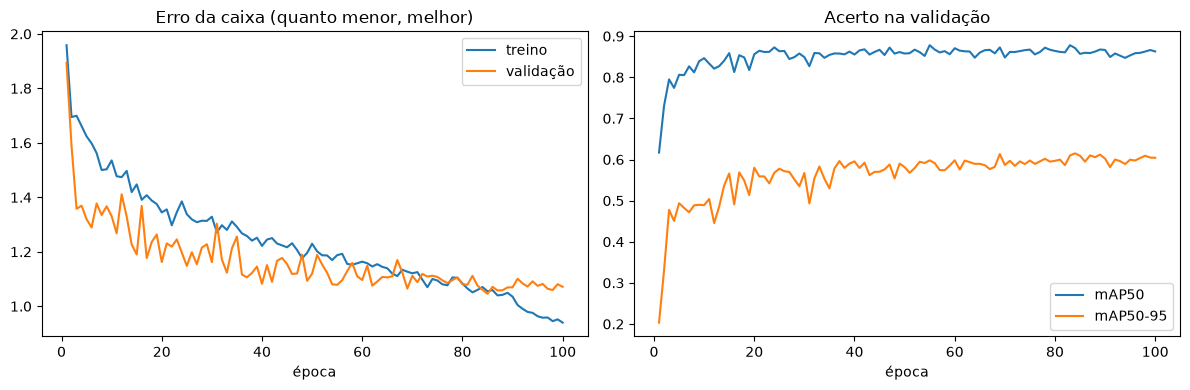

In [6]:
hist = pd.read_csv("resultados/treino.csv")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist.epoch, hist["train/box_loss"], label="treino")
ax[0].plot(hist.epoch, hist["val/box_loss"], label="validação")
ax[0].set_title("Erro da caixa (quanto menor, melhor)"); ax[0].set_xlabel("época"); ax[0].legend()
ax[1].plot(hist.epoch, hist["metrics/mAP50(B)"], label="mAP50")
ax[1].plot(hist.epoch, hist["metrics/mAP50-95(B)"], label="mAP50-95")
ax[1].set_title("Acerto na validação"); ax[1].set_xlabel("época"); ax[1].legend()
plt.tight_layout(); plt.savefig("resultados/treino.png", dpi=110); plt.show()

## 3. Resultados no conjunto de teste

Imagens não usadas no treinamento nem na seleção do melhor modelo.
- **Precisão:** proporção das caixas detectadas que estavam corretas.
- **Recall:** proporção das luminárias existentes que foram detectadas.
- **mAP50:** métrica geral de 0 a 1; acerto quando a caixa prevista sobrepõe ao menos 50% da anotada.
- **mAP50-95:** a mesma métrica, exigindo sobreposição de 50% a 95%.

In [7]:
m = YOLO("modelo/luzviva.pt").val(data=str(DATASET / "data.yaml"), split="test", project=PASTA / "runs", name="teste",
                                   exist_ok=True, verbose=False)
tabela = pd.DataFrame({"precisão": m.box.p, "recall": m.box.r, "mAP50": m.box.ap50, "mAP50-95": m.box.ap}, index=CLASSES)
tabela.loc["todas"] = tabela.mean()
tabela.round(3).to_csv("resultados/metricas_teste.csv")
tabela.round(3)

,precisão,recall,mAP50,mAP50-95
acesa,0.841,0.838,0.905,0.682
apagada,0.655,0.697,0.638,0.359
todas,0.748,0.767,0.771,0.520


Matriz de confusão: colunas são a classe real e linhas, a previsão. "não marcou" são luminárias não detectadas e
"era fundo", caixas sem luminária (falsos positivos). Usa o limiar de confiança 0,4 da interface (o mAP acima considera todas).

In [8]:
m40 = YOLO("modelo/luzviva.pt").val(data=str(DATASET / "data.yaml"), split="test", conf=0.4, project=PASTA / "runs",
                                     name="teste", exist_ok=True, verbose=False)
cm = pd.DataFrame(m40.confusion_matrix.matrix.astype(int),
                  index=["disse acesa", "disse apagada", "não marcou"],
                  columns=["era acesa", "era apagada", "era fundo"])
shutil.copy("runs/teste/confusion_matrix.png", "resultados/matriz_confusao.png")
cm

,era acesa,era apagada,era fundo
disse acesa,221,1,38
disse apagada,2,61,30
não marcou,42,27,0


**Análise:** a confusão entre classes é mínima (3 trocas em 354 luminárias). O erro predominante é a **não detecção**:
27 das 89 apagadas não foram encontradas, por serem pequenas, escuras e com menos exemplos (555 caixas contra 3.108 de
acesa). Houve também 68 falsos positivos.

**Efeito das 100 imagens complementares:** sem elas, o mAP50 era 0,79 (agora 0,77), mas o recall da apagada subiu de
0,66 para 0,70 e o da acesa, de 0,79 para 0,84. O novo modelo foi mantido porque, no LuzViva, uma apagada não detectada
é mais grave que um alarme falso. O teste tem poucas apagadas noturnas, então não avalia bem esse cenário.

## 4. Exemplos

As 5 imagens de exemplo da interface (conjunto de teste, pessoas e veículos desfocados), com o mesmo recorte do site:
o modelo analisa o quadro inteiro e a imagem mostra apenas a área das luminárias. Verde = acesa, vermelho = apagada.

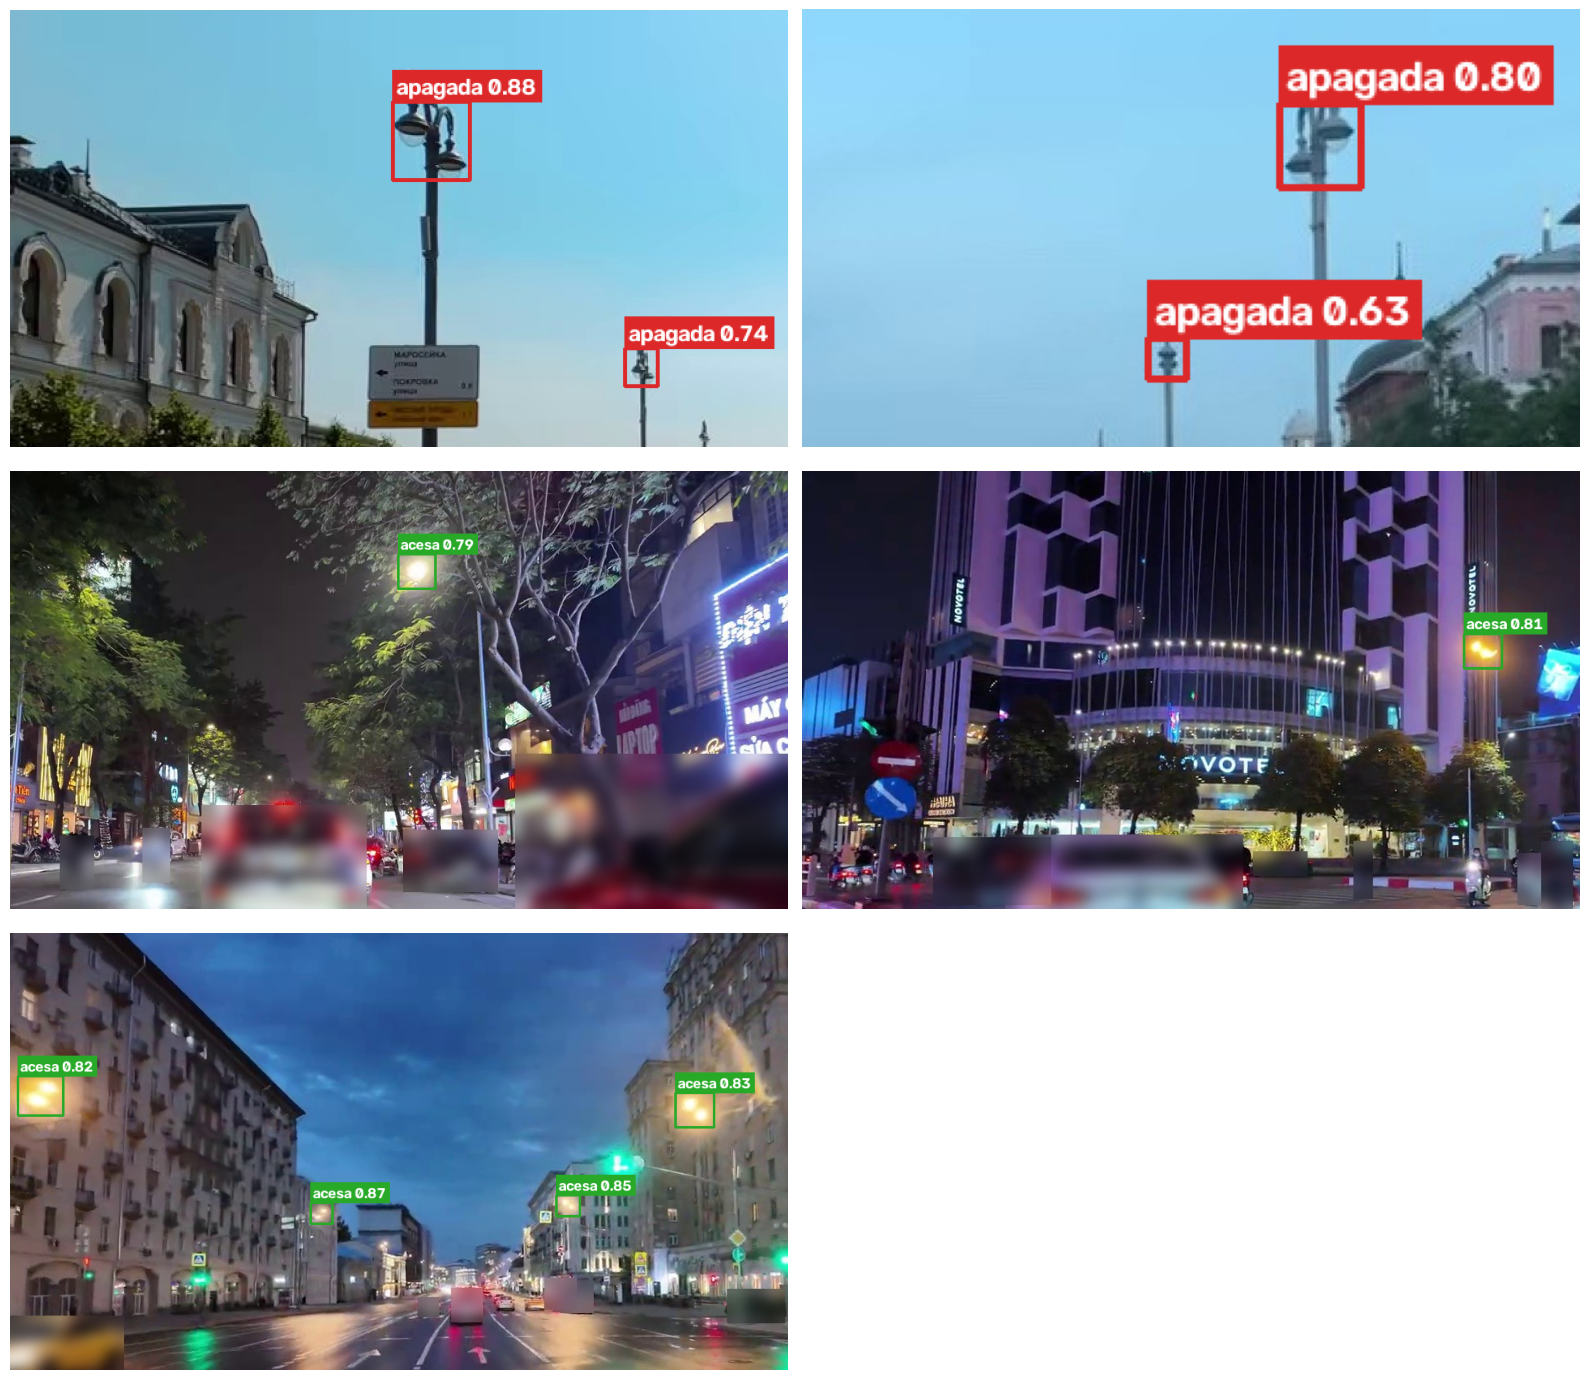

In [9]:
from app import RECORTES, abrir_exemplo  # área de cada exemplo mostrada no site

fig, ax = plt.subplots(3, 2, figsize=(16, 14))
for a, nome in zip(ax.flat, RECORTES):
    img = abrir_exemplo(nome)
    x, y, w, h = RECORTES[nome]
    a.imshow(cv2.cvtColor(desenhar(img, detectar(img))[y:y + h, x:x + w], cv2.COLOR_BGR2RGB)); a.axis("off")
ax.flat[-1].axis("off")
plt.tight_layout(); plt.savefig("resultados/exemplos.jpg", dpi=60); plt.show()

## 5. Tempo real

Em uma câmera, o modelo precisa analisar cada quadro rapidamente. O tempo foi medido nas 178 imagens de teste,
carregadas antes, como chegariam da câmera:

In [10]:
# caminho relativo: o cv2.imread não abre caminho com acento ("Visão")
quadros = [cv2.imread(str(f)) for f in sorted(Path("dataset/test/images").glob("*.jpg"))]
detectar(quadros[0])  # a 1ª chamada é mais lenta (aquece a GPU)
inicio = time.time()
for q in quadros:
    detectar(q)
ms = (time.time() - inicio) * 1000 / len(quadros)
print(f"{ms:.1f} ms por foto = {1000 / ms:.0f} quadros por segundo")

20.3 ms por foto = 49 quadros por segundo


Cerca de 20 ms por imagem, ou aproximadamente 50 quadros por segundo. Como uma câmera convencional grava 30, o modelo
opera em tempo real. Na interface, cada exemplo é processado como um quadro da câmera, com o tempo exibido no resultado.